In [1]:
import numpy as np
from scipy.stats import multivariate_normal
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm
from tqdm import tqdm
from Nonparametric.kernel import kernel_density

# Wishart matrix with single variance component
This notebook reproduces the simulation presented in Appendix D.1.

## Model Setup
When $k=1$, let 
$$
Y = U_1X\Sigma^{1/2},
$$
where $U_1=\text{Id}_n$, $X\in\mathbb{R}^{n\times p}$ has i.i.d. standard Gaussian entries and $\Sigma \in \mathbb{R}^{p\times p}$ is positive semidefinite. Setting $B=(p/n)\text{Id}_n$, the quadratic form matrix becomes 
$$
S_n = \frac{1}{p}Y^TBY = \frac{1}{n}\Sigma^{1/2}X^TX\Sigma^{1/2}. 
$$
This matches the single-component Wishart setting considered in [1]. We specialize our estimator to this setting and compare it with the method of [1].

[1] Olivier Ledoit and Michael Wolf. “Analytical nonlinear shrinkage of large-dimensional covariance matrices”. In: The Annals of Statistics 48.5 (2020), pp. 3043–3065.

## Oracle estimator

In [ ]:
n=100
p=50
Sigma_diag = np.arange(p, 0, -1) / p
Sigma =  np.diag(Sigma_diag)
np.random.seed(1)
Y = multivariate_normal.rvs(mean=np.zeros(p), cov=Sigma, size=n)
Sn = (Y.T @ Y) / n

Lambda, U = np.linalg.eigh(Sn)
isort = np.argsort(Lambda)[::-1]
Lambda = Lambda[isort]
U = U[:, isort]

d_oracle = np.diag(U.T@Sigma@U)  

## Ledoit and Wolf's estimator v.s. Our estimator 
In Section 4.7 of [1], an analytical formula is given for the shrinkage estimator. As derived in Appendix D, when specialized to the Wishart setting, our bona fide nonparametric estimator also admits an analytical formula.

In [ ]:
cn=p/n
f_hat, Hf_hat = kernel_density(Lambda,n, eps=0.)
d_hat_LW = Lambda/((1-cn-cn*Lambda*np.pi*Hf_hat)**2+(cn*Lambda*np.pi*f_hat)**2)

g_hat, Hg_hat = kernel_density(Lambda, n, T=Lambda*p/n,eps=0.)
d_hat_ours = g_hat/f_hat*1/((1-np.pi*Hg_hat)**2+(np.pi*g_hat)**2)*n/p

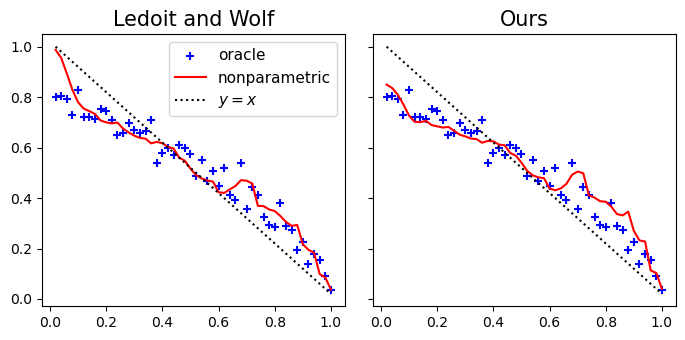

In [31]:
_, axes = plt.subplots(1, 2, figsize=(7, 3.5), sharex=True, sharey=True)

x = np.sort(Sigma_diag)

axes[0].scatter(x, d_oracle, label='oracle', color='b', marker='+')
axes[0].plot(x, d_hat_LW, label='nonparametric', color='r')
axes[0].plot(x, Sigma_diag, ':', color='black', label=r'$y=x$')
axes[0].legend(fontsize = 11)
axes[0].set_title('Ledoit and Wolf', fontsize = 15)

axes[1].scatter(x, d_oracle, label='oracle', color='b', marker='+')
axes[1].plot(x, d_hat_ours, label='nonparametric', color='r')
axes[1].plot(x, Sigma_diag, ':', color='black', label=r'$y=x$')
axes[1].set_title('Ours', fontsize = 15)

plt.tight_layout()
plt.savefig('image/wishart_compare.pdf')
plt.show()